<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Ciência e Engenharia dos Materiais com Python — Análise de Propriedades e Caracterização.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

A Ciência e Engenharia dos Materiais relaciona estrutura, processamento, propriedades e desempenho. Para interpretar uma medida experimental, o engenheiro deve compreender o fenômeno físico que produz o sinal, suas unidades e as hipóteses do modelo. Este notebook desenvolve exemplos de caracterização estrutural, comportamento mecânico, transporte e espectroscopia, seguindo a sequência **fenômeno → modelo → cálculo manual → algoritmo → código Python → interpretação**.

Os dados são **sintéticos e didáticos**: não constituem resultados de ensaios reais nem substituem normas de caracterização ou análise de incerteza metrológica. As unidades e aproximações serão explicitadas em cada aplicação.

**Objetivos:** calcular parâmetros cristalográficos, interpretar difração, analisar curvas tensão–deformação, simular fenômenos térmicos e difusivos, ajustar modelos e verificar a plausibilidade física dos resultados.

**Sumário**

1. [O problema de Engenharia dos Materiais](#secao-1)
2. [Ambiente computacional e unidades](#secao-2)
3. [Estrutura cristalina e parâmetros de rede](#secao-3)
4. [Difração de raios X e lei de Bragg](#secao-4)
5. [Difratograma sintético e identificação de picos](#secao-5)
6. [Tamanho de cristalito e equação de Scherrer](#secao-6)
7. [Densidade teórica de estruturas cristalinas](#secao-7)
8. [Ensaios de tração e curvas tensão–deformação](#secao-8)
9. [Módulo de elasticidade por regressão](#secao-9)
10. [Dilatação térmica e tensões térmicas](#secao-10)
11. [Condução térmica em materiais](#secao-11)
12. [Difusão e segunda lei de Fick](#secao-12)
13. [Cinética térmica e equação de Arrhenius](#secao-13)
14. [Materiais compósitos e regra das misturas](#secao-14)
15. [Propriedades elétricas e resistividade](#secao-15)
16. [Espectroscopia Raman: posição e largura de bandas](#secao-16)
17. [Tratamento de sinais experimentais](#secao-17)
18. [Projeto integrador: caracterização de um material](#secao-18)
19. [Verificação de resultados e limitações](#secao-19)
20. [Exercícios e conclusões](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O problema de Engenharia dos Materiais</div>

**Problema de Engenharia.** Dois materiais podem apresentar composição química semelhante e propriedades muito diferentes. A estrutura cristalina, a microestrutura, os defeitos e o processamento influenciam resistência, condutividade, estabilidade e resposta térmica.

Uma caracterização confiável não termina quando um programa fornece um número: é necessário relacionar a grandeza calculada ao mecanismo físico, verificar a unidade e reconhecer as limitações do modelo.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Ambiente computacional e unidades</div>

Usaremos `numpy`, `matplotlib` e `scipy`, bibliotecas já introduzidas na coleção. Quando necessário, instale pelo terminal `python -m pip install numpy matplotlib scipy`. Usaremos unidades SI nos cálculos e converteremos explicitamente nanômetros, ångströms e graus.

**Conversões úteis:** $1\,\mathrm{nm}=10^{-9}\,\mathrm{m}$; $1\,\mathrm{\AA}=10^{-10}\,\mathrm{m}$; $1\,\mathrm{GPa}=10^9\,\mathrm{Pa}$.

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
rng = np.random.default_rng(2026)
print('Bibliotecas carregadas.')

Bibliotecas carregadas.


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Estrutura cristalina e parâmetros de rede</div>

**Cristalografia.** Em um cristal cúbico, o espaçamento entre planos de índices de Miller $(hkl)$ é

$$d_{hkl}=\frac{a}{\sqrt{h^2+k^2+l^2}},$$

em que $a$ é o parâmetro de rede. Para $a=0{,}400$ nm e o plano (200), obtemos manualmente $d_{200}=0{,}400/2=0{,}200$ nm. A relação geométrica não indica, sozinha, se uma reflexão será observada: o fator de estrutura e a simetria também importam.

In [38]:
a_nm = 0.400
indices = [(1,1,1),(2,0,0),(2,2,0)]
for h,k,l in indices:
    d_nm = a_nm / np.sqrt(h*h+k*k+l*l)
    print(f'({h}{k}{l}): d = {d_nm:.4f} nm')

(111): d = 0.2309 nm
(200): d = 0.2000 nm
(220): d = 0.1414 nm


<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Difração de raios X e lei de Bragg</div>

**Difração de raios X (DRX).** A interferência construtiva para planos cristalinos é descrita pela lei de Bragg:

$$n\lambda=2d\sin\theta.$$

Para $n=1$, $\lambda=0{,}15406$ nm (Cu Kα, aproximação monocromática) e $d=0{,}200$ nm, resulta $\theta=\arcsin(0{,}15406/0{,}400)\approx22{,}65^\circ$, portanto $2\theta\approx45{,}30^\circ$.

**Atenção:** o difratômetro normalmente apresenta o eixo em $2\theta$, não em $\theta$.

In [39]:
lambda_nm = 0.15406
d_nm = 0.200
razao = lambda_nm/(2*d_nm)
if not 0 <= razao <= 1:
    raise ValueError('Não há ângulo de Bragg real para estes dados.')
theta_graus = np.degrees(np.arcsin(razao))
print(f'theta = {theta_graus:.3f}°; 2theta = {2*theta_graus:.3f}°')

theta = 22.653°; 2theta = 45.306°


<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Difratograma sintético e identificação de picos</div>

**Formação de um difratograma.** O detector registra intensidade em função de $2\theta$. Picos representam condições de interferência construtiva; sua posição depende dos espaçamentos interplanares, e suas intensidades dependem, entre outros fatores, da estrutura cristalina, orientação preferencial e geometria experimental.

Simularemos três picos gaussianos sobre uma linha de base e adicionaremos ruído. **Esses picos não representam uma fase real identificada**: são sinais didáticos para exercitar localização de máximos.

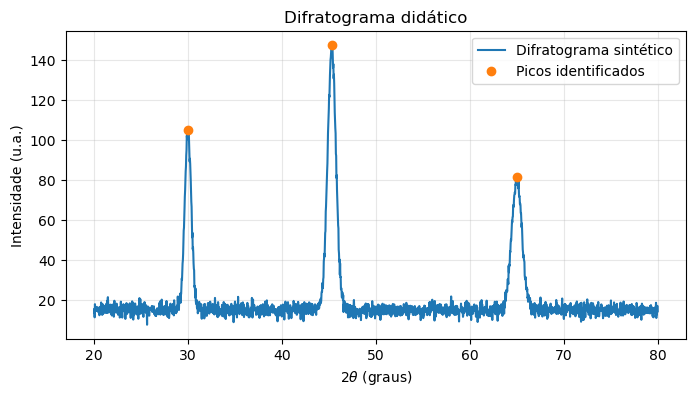

Picos (2theta): [29.96 45.29 64.97]


In [40]:
ang = np.linspace(20,80,2001)
def gauss(x,centro,largura,amplitude):
    return amplitude*np.exp(-0.5*((x-centro)/largura)**2)
intensidade_ideal = (15 + gauss(ang,30,0.35,90)
                     + gauss(ang,45.3,0.45,130)
                     + gauss(ang,65,0.55,65))
intensidade = intensidade_ideal + rng.normal(0,2,len(ang))
picos,_ = find_peaks(intensidade,prominence=30,distance=150)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(ang,intensidade,label='Difratograma sintético')
ax.plot(ang[picos],intensidade[picos],'o',label='Picos identificados')
ax.set(xlabel=r'$2\theta$ (graus)',ylabel='Intensidade (u.a.)',title='Difratograma didático')
ax.grid(alpha=.3);ax.legend();plt.show()
print('Picos (2theta):',np.round(ang[picos],2))

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Tamanho de cristalito e equação de Scherrer</div>

**Tamanho de cristalito.** Sob hipóteses adequadas, o alargamento de um pico de DRX pode ser relacionado ao tamanho de domínio coerente por meio da equação de Scherrer:

$$D=\frac{K_s\lambda}{\beta\cos\theta},$$

em que $K_s$ é o fator de forma, $\beta$ é a largura à meia altura (FWHM) em **radianos de $2\theta$**, corrigida do alargamento instrumental, e $\theta$ é o ângulo de Bragg. Para perfis gaussianos, uma aproximação é $\beta=\sqrt{\beta_{obs}^2-\beta_{inst}^2}$.

**Exemplo manual:** $K_s=0{,}9$, $\lambda=0{,}15406$ nm, $2\theta=40^\circ$, $\beta_{obs}=0{,}30^\circ$, $\beta_{inst}=0{,}10^\circ$. O resultado não é o tamanho de partícula: microdeformação e outras fontes de alargamento podem afetar a estimativa.

In [41]:
K_s=0.9
beta_obs_graus=0.30
beta_inst_graus=0.10
if beta_obs_graus <= beta_inst_graus:
    raise ValueError('Largura observada insuficiente para esta correção.')
beta_rad=np.deg2rad(np.sqrt(beta_obs_graus**2-beta_inst_graus**2))
theta_rad=np.deg2rad(40/2)
D_nm=K_s*lambda_nm/(beta_rad*np.cos(theta_rad))
print(f'Largura corrigida = {np.rad2deg(beta_rad):.4f}°; D = {D_nm:.2f} nm')

Largura corrigida = 0.2828°; D = 29.89 nm


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Densidade teórica de estruturas cristalinas</div>

**Densidade teórica.** Em uma célula unitária, a densidade é

$$\rho=\frac{nM}{N_Aa^3},$$

onde $n$ é o número de átomos por célula, $M$ a massa molar e $a$ o parâmetro de rede cúbico. Para um metal hipotético CFC, $n=4$. Com $M=63{,}55$ g/mol e $a=0{,}3615$ nm, convertemos a massa para kg/mol e $a$ para metros antes de calcular $\rho$ em kg/m³. O valor obtido é uma previsão ideal, não uma medida de densidade aparente.

In [42]:
NA=6.02214076e23
n_atom=4
M_kg_mol=63.55e-3
a_m=0.3615e-9
rho=n_atom*M_kg_mol/(NA*a_m**3)
print(f'Densidade teórica: {rho:.1f} kg/m³ = {rho/1000:.3f} g/cm³')

Densidade teórica: 8935.1 kg/m³ = 8.935 g/cm³


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Ensaios de tração e curvas tensão–deformação</div>

**Ensaio de tração.** A tensão e a deformação de engenharia são

$$\sigma=\frac{F}{A_0},\qquad \varepsilon=\frac{L-L_0}{L_0}.$$

Para uma força de 10 kN e seção inicial de 50 mm², $\sigma=10\,000/(50\times10^{-6})=200$ MPa. Se $L_0=50$ mm e o alongamento é 0,05 mm, $\varepsilon=0{,}001$. Uma curva tensão–deformação permite identificar a região elástica e outras características, desde que os dados sejam adquiridos e interpretados conforme o método de ensaio.

In [43]:
F_N=10_000
A0_m2=50e-6
L0_mm=50.0
dL_mm=0.05
sigma_MPa=F_N/A0_m2/1e6
epsilon=dL_mm/L0_mm
print(f'Tensão = {sigma_MPa:.1f} MPa; deformação = {epsilon:.5f}')

Tensão = 200.0 MPa; deformação = 0.00100


<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Módulo de elasticidade por regressão</div>

**Lei de Hooke e regressão.** Na região elástica linear, $\sigma=E\varepsilon$, em que $E$ é o módulo de Young. Se $\sigma=200$ MPa para $\varepsilon=0{,}001$, então $E=200$ GPa.

Na prática, ajustamos uma reta a vários pares de medidas **somente na região linear**. O intercepto pode representar offset experimental; uma regressão em toda a curva, inclusive após o escoamento, não fornece corretamente o módulo elástico.

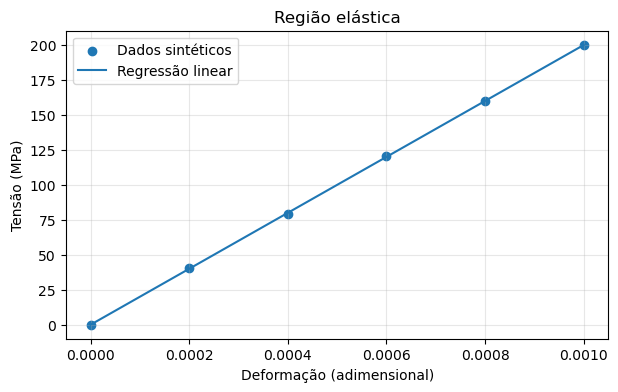

E estimado = 200.23 GPa; intercepto = -0.014 MPa


In [44]:
deformacao=np.array([0,0.0002,0.0004,0.0006,0.0008,0.0010])
tensao_MPa=np.array([0.0,40.3,79.5,120.6,159.8,200.4])
E_MPa,intercepto=np.polyfit(deformacao,tensao_MPa,1)
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(deformacao,tensao_MPa,label='Dados sintéticos')
ax.plot(deformacao,E_MPa*deformacao+intercepto,label='Regressão linear')
ax.set(xlabel='Deformação (adimensional)',ylabel='Tensão (MPa)',title='Região elástica')
ax.grid(alpha=.3);ax.legend();plt.show()
print(f'E estimado = {E_MPa/1000:.2f} GPa; intercepto = {intercepto:.3f} MPa')

<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Dilatação térmica e tensões térmicas</div>

**Dilatação térmica.** Para variações moderadas e coeficiente constante, a deformação térmica livre é $\varepsilon_T=\alpha\Delta T$, e o alongamento é $\Delta L=\alpha L_0\Delta T$.

Para $\alpha=12\times10^{-6}$ K⁻¹, $L_0=1$ m e $\Delta T=50$ K, resulta $\Delta L=0{,}0006$ m, ou 0,6 mm. Se a expansão uniaxial for completamente impedida e o comportamento for linear elástico, a tensão térmica idealizada é $\sigma=-E\alpha\Delta T$ (compressão para aquecimento). Em peças reais, geometria, apoios e plasticidade alteram esse resultado.

In [45]:
alpha=12e-6
L0_m=1.0
deltaT_K=50.0
E_Pa=200e9
deltaL_mm=alpha*L0_m*deltaT_K*1000
sigma_termica_MPa=-E_Pa*alpha*deltaT_K/1e6
print(f'Alongamento livre = {deltaL_mm:.3f} mm')
print(f'Tensão ideal sob restrição total = {sigma_termica_MPa:.1f} MPa')

Alongamento livre = 0.600 mm
Tensão ideal sob restrição total = -120.0 MPa


<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Condução térmica em materiais</div>

**Condução de calor.** Em uma parede plana homogênea, sob regime permanente e condução unidimensional, a lei de Fourier conduz a

$$\dot Q=kA\frac{T_q-T_f}{L}.$$

Para $k=15$ W/(m·K), $A=0{,}5$ m², $L=0{,}10$ m e $\Delta T=40$ K, $\dot Q=3000$ W. A condutividade térmica é uma propriedade do material e pode depender de temperatura, direção e microestrutura.

Taxa de condução: 3000 W


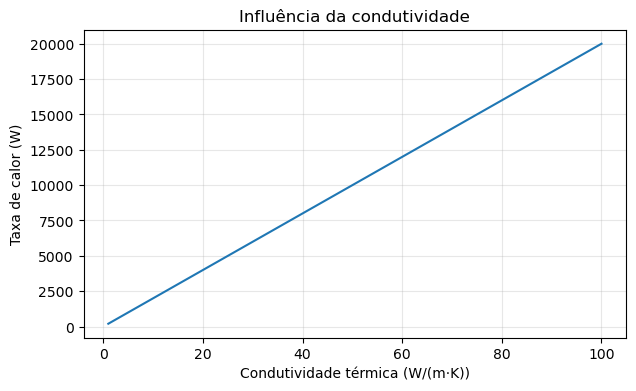

In [46]:
k=15.0; area=0.5; espessura=0.10; deltaT=40.0
q_W=k*area*deltaT/espessura
print(f'Taxa de condução: {q_W:.0f} W')
ks=np.linspace(1,100,100)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(ks,ks*area*deltaT/espessura)
ax.set(xlabel='Condutividade térmica (W/(m·K))',ylabel='Taxa de calor (W)',title='Influência da condutividade')
ax.grid(alpha=.3);plt.show()

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Difusão e segunda lei de Fick</div>

**Difusão em sólidos.** A segunda lei de Fick para coeficiente constante e uma dimensão é

$$\frac{\partial C}{\partial t}=D\frac{\partial^2C}{\partial x^2}.$$

Discretizando o espaço e o tempo com diferenças finitas explícitas:

$$C_i^{n+1}=C_i^n+r(C_{i+1}^n-2C_i^n+C_{i-1}^n),\quad r=\frac{D\Delta t}{\Delta x^2}.$$

Para essa discretização, $r\leq0{,}5$ é a condição clássica de estabilidade. Simularemos uma distribuição inicialmente concentrada no centro, com fronteiras de fluxo nulo. As unidades de concentração são arbitrárias; o modelo é idealizado.

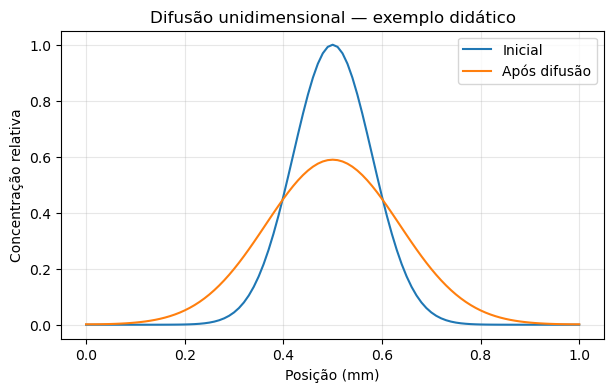

Número de estabilidade r = 0.40; tempo simulado = 60.00 s


In [47]:
D=1e-10
comprimento=1e-3
nx=101
x=np.linspace(0,comprimento,nx)
dx=x[1]-x[0]
dt=0.4*dx**2/D
r=D*dt/dx**2
C=np.exp(-0.5*((x-comprimento/2)/(0.08e-3))**2)
C_inicial=C.copy()
for passo in range(150):
    anterior=C.copy()
    C[1:-1]=anterior[1:-1]+r*(anterior[2:]-2*anterior[1:-1]+anterior[:-2])
    C[0]=C[1];C[-1]=C[-2]
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(x*1e3,C_inicial,label='Inicial')
ax.plot(x*1e3,C,label='Após difusão')
ax.set(xlabel='Posição (mm)',ylabel='Concentração relativa',title='Difusão unidimensional — exemplo didático')
ax.grid(alpha=.3);ax.legend();plt.show()
print(f'Número de estabilidade r = {r:.2f}; tempo simulado = {150*dt:.2f} s')

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Cinética térmica e equação de Arrhenius</div>

**Dependência com a temperatura.** Muitos processos termicamente ativados podem ser aproximados pela relação de Arrhenius:

$$D(T)=D_0\exp\left(-\frac{Q}{RT}\right).$$

Aqui $Q$ é a energia de ativação (J/mol), $R=8{,}314$ J/(mol·K) e $T$ é a temperatura **absoluta**, em kelvin. Para $D_0=10^{-5}$ m²/s, $Q=120$ kJ/mol e $T=1000$ K, obtemos $D\approx5{,}4\times10^{-12}$ m²/s. Nunca se deve substituir °C diretamente na expressão exponencial.

D(1000 K) = 5.395e-12 m²/s


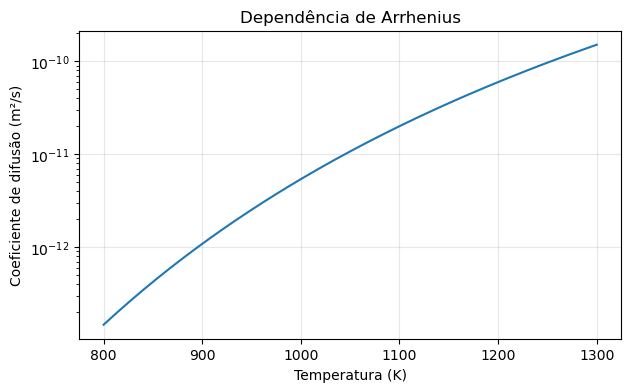

In [48]:
D0=1e-5
Q=120e3
R=8.314462618
T_K=np.linspace(800,1300,150)
D_T=D0*np.exp(-Q/(R*T_K))
print(f'D(1000 K) = {D0*np.exp(-Q/(R*1000)):.3e} m²/s')
fig,ax=plt.subplots(figsize=(7,4))
ax.semilogy(T_K,D_T)
ax.set(xlabel='Temperatura (K)',ylabel='Coeficiente de difusão (m²/s)',title='Dependência de Arrhenius')
ax.grid(alpha=.3);plt.show()

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Materiais compósitos e regra das misturas</div>

**Materiais compósitos.** Uma estimativa simples do módulo longitudinal de um compósito com fibras alinhadas e deformação uniforme é a regra das misturas:

$$E_L=V_fE_f+(1-V_f)E_m.$$

Para $V_f=0{,}40$, $E_f=200$ GPa e $E_m=3$ GPa, obtemos $E_L=0{,}4(200)+0{,}6(3)=81{,}8$ GPa. Trata-se de uma aproximação idealizada: orientação, adesão, porosidade e distribuição das fibras alteram o desempenho real.

E longitudinal em Vf=0,40: 81.80 GPa


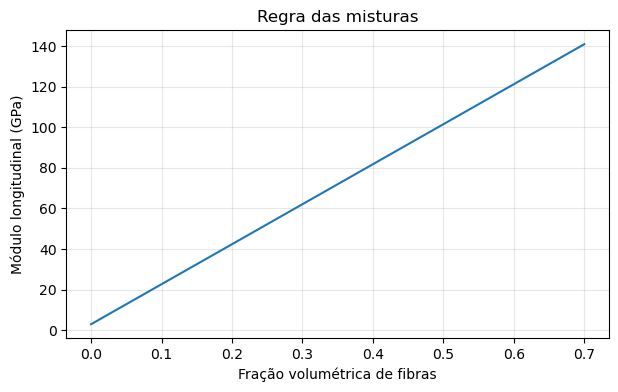

In [49]:
Vf=np.linspace(0,0.7,101)
Ef=200.0;Em=3.0
EL=Vf*Ef+(1-Vf)*Em
print(f'E longitudinal em Vf=0,40: {0.4*Ef+0.6*Em:.2f} GPa')
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(Vf,EL)
ax.set(xlabel='Fração volumétrica de fibras',ylabel='Módulo longitudinal (GPa)',title='Regra das misturas')
ax.grid(alpha=.3);plt.show()

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Propriedades elétricas e resistividade</div>

**Resistividade elétrica.** Para um corpo homogêneo de seção uniforme, $R_e=\rho_e L/A$, em que $R_e$ é a resistência elétrica (Ω) e $\rho_e$ a resistividade (Ω·m). A condutividade é $\sigma_e=1/\rho_e$.

Para $\rho_e=1{,}7\times10^{-8}$ Ω·m, $L=2$ m e $A=1$ mm², a resistência estimada é $R_e=0{,}034$ Ω. A relação supõe temperatura e geometria conhecidas; contatos e anisotropia podem influenciar medidas reais.

In [50]:
rho_e=1.7e-8
L=2.0
A=1e-6
Re=rho_e*L/A
sigma_e=1/rho_e
print(f'Resistência = {Re:.4f} Ω; condutividade = {sigma_e:.3e} S/m')

Resistência = 0.0340 Ω; condutividade = 5.882e+07 S/m


<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Espectroscopia Raman: posição e largura de bandas</div>

**Espectroscopia Raman.** Na caracterização de materiais, a posição, a largura e a intensidade de bandas Raman podem fornecer informações sobre vibrações e estrutura. A forma do espectro depende do material e das condições instrumentais.

Representaremos uma banda **sintética** com perfil lorentziano:

$$I(\nu)=I_0+\frac{A}{1+4[(\nu-\nu_0)/w]^2},$$

onde $\nu_0$ é o centro e $w$ é a largura à meia altura (FWHM). A identificação de bandas de um material real exige referências espectroscópicas e avaliação de efeitos como fluorescência, linha de base e resolução instrumental.

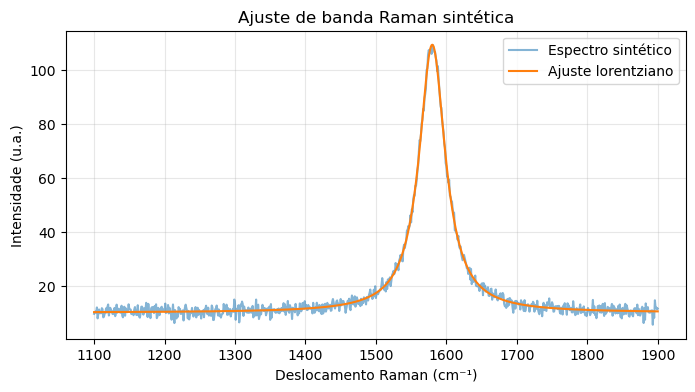

Centro = 1579.97 cm⁻¹; FWHM = 45.02 cm⁻¹


In [51]:
def lorentz(nu,I0,A,nu0,w):
    return I0+A/(1+4*((nu-nu0)/w)**2)
nu=np.linspace(1100,1900,801)
sinal_raman=lorentz(nu,10,100,1580,45)+rng.normal(0,1.5,len(nu))
param,_=curve_fit(lorentz,nu,sinal_raman,p0=[10,100,1580,45],bounds=([0,0,1100,1],[100,500,1900,200]))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(nu,sinal_raman,label='Espectro sintético',alpha=.55)
ax.plot(nu,lorentz(nu,*param),label='Ajuste lorentziano')
ax.set(xlabel='Deslocamento Raman (cm⁻¹)',ylabel='Intensidade (u.a.)',title='Ajuste de banda Raman sintética')
ax.grid(alpha=.3);ax.legend();plt.show()
print(f'Centro = {param[2]:.2f} cm⁻¹; FWHM = {param[3]:.2f} cm⁻¹')

<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Tratamento de sinais experimentais</div>

**Tratamento de sinais.** Uma linha de base inadequada ou ruído excessivo pode deslocar os parâmetros de ajuste. A análise deve distinguir sinal físico, fundo instrumental e ruído. Para demonstrar o efeito, subtrairemos uma linha de base **conhecida na simulação** e calcularemos a intensidade integrada por integração numérica.

Em um experimento real, a linha de base não é necessariamente conhecida e sua estimativa exige critérios apropriados; a integral não pode ser interpretada diretamente como concentração sem calibração e modelo físico.

In [52]:
linha_base=10.0
sinal_corrigido=sinal_raman-linha_base
area_banda=np.trapezoid(sinal_corrigido,nu) if hasattr(np,'trapezoid') else np.trapz(sinal_corrigido,nu)
print(f'Área integrada aproximada: {area_banda:.1f} u.a.·cm⁻¹')

Área integrada aproximada: 6758.5 u.a.·cm⁻¹


<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Projeto integrador: caracterização de um material</div>

**Projeto integrador — da medida à propriedade.** Um pesquisador dispõe de um pico de DRX em $2\theta=45{,}3^\circ$ com radiação Cu Kα ($\lambda=0{,}15406$ nm) e de uma curva elástica de tração. O objetivo é estimar o espaçamento interplanar e o módulo de Young.

**Cálculo manual:** pela lei de Bragg, $d=\lambda/[2\sin(\theta)]$, com $\theta=22{,}65^\circ$, resulta $d\approx0{,}200$ nm. Para um ponto de tração com $\sigma=200$ MPa e $\varepsilon=0{,}001$, $E\approx200$ GPa. A seguir, calcularemos essas propriedades e registraremos suas unidades. Não é possível identificar uma fase cristalina apenas por um pico isolado.

In [53]:
theta=np.deg2rad(45.3/2)
d_estimado=lambda_nm/(2*np.sin(theta))
E_estimado=E_MPa/1000
print(f'Espaçamento interplanar estimado: {d_estimado:.4f} nm')
print(f'Módulo elástico estimado por regressão: {E_estimado:.2f} GPa')
print('Limitação: identificação de fase requer comparação de múltiplas reflexões.')

Espaçamento interplanar estimado: 0.2000 nm
Módulo elástico estimado por regressão: 200.23 GPa
Limitação: identificação de fase requer comparação de múltiplas reflexões.


<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Verificação de resultados e limitações</div>

**Verificação de Engenharia.** Os testes computacionais ajudam a detectar erros de implementação, mas não validam sozinhos um modelo físico. Uma comparação com `np.isclose` verifica consistência numérica dentro de tolerância definida; não demonstra exatidão experimental.

Antes de interpretar os resultados, verifique: coerência das unidades, hipóteses de homogeneidade e isotropia, faixa de validade dos modelos, calibração dos instrumentos, propagação de incertezas e possibilidade de soluções alternativas. O `assert` é apropriado para testes de desenvolvimento, não para proteções operacionais.

In [54]:
assert np.isclose(a_nm/2,0.2)
assert np.isclose(sigma_MPa,200)
assert D_nm>0
assert np.isfinite(param).all()
assert 0<r<=0.5
print('Verificações numéricas didáticas concluídas.')

Verificações numéricas didáticas concluídas.


<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Exercícios e conclusões</div>

**Exercícios de consolidação**

**Exercício 1 — Cristalografia.** Para um cristal cúbico com $a=0{,}360$ nm, calcule manualmente $d_{111}$ e $d_{200}$ e confirme os resultados em Python.

**Exercício 2 — DRX.** Usando Cu Kα, determine o valor de $2\theta$ para $d=0{,}180$ nm. Explique a diferença entre $\theta$ e $2\theta$.

**Exercício 3 — Scherrer.** Calcule o tamanho de cristalito para $K_s=0{,}9$, $\beta_{obs}=0{,}25^\circ$, $\beta_{inst}=0{,}10^\circ$ e $2\theta=40^\circ$. Discuta por que tamanho de cristalito não é necessariamente tamanho de partícula.

**Exercício 4 — Mecânica.** Para força de 12 kN, seção de 60 mm² e deformação de 0,001, determine tensão e módulo elástico aparente, supondo resposta linear.

**Exercício 5 — Dilatação.** Uma barra de 1,5 m tem $\alpha=15\times10^{-6}$ K⁻¹. Determine o alongamento para aumento de 60 K.

**Exercício 6 — Difusão.** Altere o coeficiente $D$ da simulação e discuta o efeito na distribuição de concentração, preservando a condição de estabilidade numérica.

**Exercício 7 — Arrhenius.** Compare $D(900\,\mathrm{K})$ e $D(1100\,\mathrm{K})$ para os parâmetros do exemplo e interprete a sensibilidade à temperatura.

**Exercício 8 — Compósitos.** Calcule o módulo longitudinal para $V_f=0{,}25$ e $V_f=0{,}50$; explique os limites da regra das misturas.

**Desafio integrador.** Construa uma tabela de propriedades estimadas (estrutura, mecânica e transporte), indicando fórmula, unidades, hipóteses e possíveis fontes de incerteza.

**Conclusões.** A programação científica permite transformar modelos físicos em resultados verificáveis, mas a qualidade da caracterização depende da compreensão do material, do instrumento e das hipóteses empregadas. O próximo notebook reunirá as competências desenvolvidas em um projeto integrador de Engenharia Química.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>